# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [4]:
class SimpleContextManager:
    """
    A simple context window manager to handle basic token limit checking.
    For simplicity, we estimate 1 token ≈ 4 characters.
    """
    def __init__(self, token_limit: int = 100):
        self.token_limit = token_limit
        self.current_tokens = 0
        self.history = []

    def estimate_tokens(self, text: str) -> int:
        """Estimates the number of tokens in a given text (approx. 4 chars per token)."""
        if not isinstance(text, str):
            raise ValueError("Input must be a string.")
        return max(1, len(text) // 4)

    def add_message(self, message: str) -> bool:
        """
        Attempts to add a message to the history if it fits within the context window limit.
        Returns True if successful, False otherwise.
        """
        try:
            estimated_tokens = self.estimate_tokens(message)
            if self.current_tokens + estimated_tokens <= self.token_limit:
                self.history.append(message)
                self.current_tokens += estimated_tokens
                return True
            else:
                print(f"⚠️ Cannot add message. Exceeds remaining context window by {self.current_tokens + estimated_tokens - self.token_limit} tokens.")
                return False
        except Exception as e:
            print(f"❌ Error: {e}")
            return False

# Test the implementation
manager = SimpleContextManager(token_limit=30)

# Test Case 1: Standard message fits
msg1 = "Hello, how are you today?"
success1 = manager.add_message(msg1)
print(f"Added '{msg1}' (Est. {manager.estimate_tokens(msg1)} tokens): {success1}")

# Test Case 2: Adding a message that exceeds limit
msg2 = "This is an extremely long message designed to exceed the context window limitations that we established for this simple manager class."
success2 = manager.add_message(msg2)
print(f"Added long message: {success2}")

# Test Case 3: Verify current token usage
print(f"Current usage: {manager.current_tokens}/{manager.token_limit} tokens used.")

Added 'Hello, how are you today?' (Est. 6 tokens): True
⚠️ Cannot add message. Exceeds remaining context window by 9 tokens.
Added long message: False
Current usage: 6/30 tokens used.


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [5]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [6]:
class AdvancedTokenEstimator:
    """
    A more sophisticated token estimator simulating professional LLM counting behavior.
    Supports checking single strings as well as list of chat messages.
    """
    def __init__(self, char_per_token: float = 4.0, overhead_per_message: int = 3):
        if char_per_token <= 0:
            raise ValueError("char_per_token must be a positive number.")
        self.char_per_token = char_per_token
        self.overhead_per_message = overhead_per_message

    def estimate_text_tokens(self, text: str) -> int:
        if not isinstance(text, str):
            raise TypeError(f"Expected string, got {type(text).__name__}")
        cleaned_text = text.strip()
        if not cleaned_text:
            return 0
        # Standard approximation
        return max(1, int(round(len(cleaned_text) / self.char_per_token)))

    def estimate_message_tokens(self, message: Dict[str, str]) -> int:
        """Estimates tokens for a single structured message: {'role': '...', 'content': '...'}"""
        if not isinstance(message, dict):
            raise TypeError("Message must be a dictionary.")
        if "role" not in message or "content" not in message:
            raise KeyError("Message dictionary must contain 'role' and 'content' keys.")

        role_tokens = self.estimate_text_tokens(message["role"])
        content_tokens = self.estimate_text_tokens(message["content"])

        # Add metadata framing overhead
        return role_tokens + content_tokens + self.overhead_per_message

    def estimate_chat_history(self, history: List[Dict[str, str]]) -> Tuple[int, Dict[str, Any]]:
        """Calculates total tokens for a full chat thread with metadata details."""
        if not isinstance(history, list):
            raise TypeError("History must be a list of message dictionaries.")

        total_tokens = 0
        breakdown = []

        for idx, msg in enumerate(history):
            tokens = self.estimate_message_tokens(msg)
            total_tokens += tokens
            breakdown.append({"index": idx, "role": msg["role"], "tokens": tokens})

        return total_tokens, {
            "total_tokens": total_tokens,
            "message_count": len(history),
            "breakdown": breakdown
        }

# Test the Advanced implementation
try:
    estimator = AdvancedTokenEstimator(char_per_token=3.8, overhead_per_message=4)

    chat_history = [
        {"role": "system", "content": "You are a helpful assistant representing a digital twin."},
        {"role": "user", "content": "What is your context window capacity?"},
        {"role": "assistant", "content": "I can handle up to 8,000 tokens of context efficiently!"}
    ]

    total, report = estimator.estimate_chat_history(chat_history)
    print("--- Chat History Token Estimation Report ---")
    print(f"Total estimated tokens: {total}\n")
    print(json.dumps(report, indent=2))

except Exception as e:
    print(f"❌ Estimation Failed: {e}")

--- Chat History Token Estimation Report ---
Total estimated tokens: 56

{
  "total_tokens": 56,
  "message_count": 3,
  "breakdown": [
    {
      "index": 0,
      "role": "system",
      "tokens": 21
    },
    {
      "index": 1,
      "role": "user",
      "tokens": 15
    },
    {
      "index": 2,
      "role": "assistant",
      "tokens": 20
    }
  ]
}


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [7]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

[Pruning] Removed message from 'user' to respect context window.

--- System Final Status ---
{
  "total_tokens": 49,
  "limit": 60,
  "message_count": 3
}


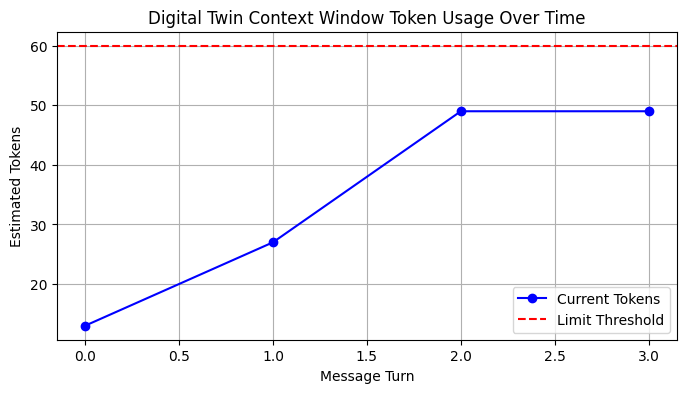

In [8]:
class ProductionSystem:
    """
    A production-ready digital twin conversation and context window manager.
    Implements a sliding window strategy to automatically prune old messages
    when the token limit is reached, tracks history, and provides telemetry.
    """
    def __init__(self, token_limit: int = 100, estimator: AdvancedTokenEstimator = None):
        self.token_limit = token_limit
        self.estimator = estimator or AdvancedTokenEstimator()
        self.history = []
        self.token_history_log = []  # To track token usage over time for visualization

    def add_message(self, role: str, content: str):
        """Adds a message and applies context pruning if it exceeds limits."""
        new_message = {"role": role, "content": content}
        self.history.append(new_message)

        # Dynamically manage the context limit using a sliding window approach
        while self.get_total_tokens() > self.token_limit and len(self.history) > 1:
            # Retain system prompt if it's the first message, otherwise pop the oldest
            if self.history[0]["role"] == "system":
                removed = self.history.pop(1)
            else:
                removed = self.history.pop(0)
            print(f"[Pruning] Removed message from '{removed['role']}' to respect context window.")

        self.token_history_log.append(self.get_total_tokens())

    def get_total_tokens(self) -> int:
        total, _ = self.estimator.estimate_chat_history(self.history)
        return total

    def get_status(self) -> Dict[str, Any]:
        return {
            "total_tokens": self.get_total_tokens(),
            "limit": self.token_limit,
            "message_count": len(self.history)
        }

    def plot_token_usage(self):
        """Visualizes token usage progression over time."""
        plt.figure(figsize=(8, 4))
        plt.plot(self.token_history_log, marker='o', color='b', label='Current Tokens')
        plt.axhline(y=self.token_limit, color='r', linestyle='--', label='Limit Threshold')
        plt.title('Digital Twin Context Window Token Usage Over Time')
        plt.xlabel('Message Turn')
        plt.ylabel('Estimated Tokens')
        plt.legend()
        plt.grid(True)
        plt.show()

# Test and verify our ProductionSystem
twin_system = ProductionSystem(token_limit=60)

# Populate history
twin_system.add_message("system", "You are a digital twin assistant.")
twin_system.add_message("user", "Hi! Tell me a bit about neural networks.")
twin_system.add_message("assistant", "Neural networks are computing systems inspired by biological brains.")
twin_system.add_message("user", "Great. Can you also explain deep learning?")

status = twin_system.get_status()
print("\n--- System Final Status ---")
print(json.dumps(status, indent=2))

# Render the context utilization chart
twin_system.plot_token_usage()

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code